# 01 - Basic Image Processing | معالجة الصور الأساسية

يجمع هذا الدفتر القراءة وتحويل الألوان وThresholding، ثم التحويلات الهندسية، ثم الفلاتر وتحسين الصور. جميع مسارات الحفظ الأصلية محفوظة كما كانت في الدفاتر الثلاثة.


---

## القسم المدمج: Image I/O, Color Conversion & Thresholding

> المصدر الأصلي: `01_Image_IO_Color_Conversion.ipynb`. تم الحفاظ على مسارات البيانات والمخرجات الأصلية، مع إعادة تسمية بعض المتغيرات/الدوال فقط لمنع التعارض داخل الدفتر الموحّد.


## 01 - قراءة الصور وتحويل الألوان وThresholding

يغطي هذا الدفتر أساسيات LAB1 وLAB2، ويحوّل الأكواد إلى وظائف منظمة يمكن نقل منطقها لاحقًا إلى Kotlin وOpenCV Android.

## أهداف الدفتر

- قراءة صورة وفحص خصائصها.
- فهم الفرق بين BGR وRGB.
- التحويل إلى Grayscale.
- التحويل إلى Binary باستخدام Threshold.
- مقارنة قيم Threshold مختلفة.
- تطبيق Threshold يدويًا باستخدام NumPy.
- حفظ النتائج.

In [1]:
from google.colab import drive
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ربط Google Drive
drive.mount("/content/drive")

# مسار المجلد الرئيسي للمشروع
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "VisionStudio_Android_ImageProcessing"
)

# مسارات الإدخال والنتائج
IO_INPUT_DIR = PROJECT_ROOT / "02_Data/Images/Input"
IO_TEST_DIR = PROJECT_ROOT / "02_Data/Images/Test"
IO_OUTPUT_DIR = PROJECT_ROOT / "04_Outputs/Images"

# التأكد من وجود المجلدات
IO_INPUT_DIR.mkdir(parents=True, exist_ok=True)
IO_TEST_DIR.mkdir(parents=True, exist_ok=True)
IO_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# عرض المسارات للتأكد
print("Project folder:", PROJECT_ROOT)
print("Input folder:", IO_INPUT_DIR)
print("Output folder:", IO_OUTPUT_DIR)
print("Project exists:", PROJECT_ROOT.exists())

Mounted at /content/drive
Project folder: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing
Input folder: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output folder: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images
Project exists: True


## دوال العرض والمعالجة

يستخدم OpenCV ترتيب BGR، بينما تستخدم Matplotlib ترتيب RGB. لذلك نُحوّل الصورة قبل عرضها.

In [2]:
def show_image(image, title='Image', cmap=None):
    if image.ndim == 3:
        display_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    else:
        display_image = image
        cmap = cmap or 'gray'

    plt.figure(figsize=(7, 5))
    plt.imshow(display_image, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()


def to_grayscale(image):
    if image is None:
        raise ValueError('The input image is empty.')
    if image.ndim == 2:
        return image.copy()
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def apply_binary_threshold(gray_image, threshold_value=127):
    if not 0 <= threshold_value <= 255:
        raise ValueError('Threshold must be between 0 and 255.')
    _, binary = cv2.threshold(
        gray_image, threshold_value, 255, cv2.THRESH_BINARY
    )
    return binary

## اختيار صورة الإدخال

- اترك `USE_UPLOAD = False` لتشغيل الدفتر بصورة اختبار يتم إنشاؤها تلقائيًا.
- غيّرها إلى `True` في Google Colab لرفع صورة من جهازك.

عدد الصور الموجودة مسبقًا: 4

الصور المتاحة:
1. R.jpeg
2. balloons.jpg
3. children.jpeg
4. coins.jpg

الصورة المختارة: R.jpeg
الأبعاد: (736, 736, 3)
عدد العناصر: 1625088
نوع البيانات: uint8


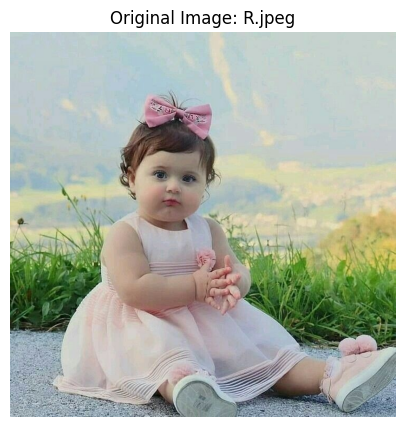

In [16]:
# ============================================================
# قراءة الصور الموجودة في Google Drive
# مع إمكانية رفع صور جديدة عند الحاجة فقط
# ============================================================

# اجعلها True فقط عندما تريد إضافة صور جديدة
UPLOAD_NEW_FILES = False

# اكتب اسم صورة محددة، أو اتركه فارغًا لاختيار أول صورة
SELECTED_IMAGE_NAME = ""

# صيغ الصور المدعومة
SUPPORTED_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

# سيحتوي على جميع الصور المقروءة
uploaded_images = {}


# ============================================================
# 1. قراءة الصور الموجودة مسبقًا داخل مجلد Input
# ============================================================

existing_image_paths = sorted([
    path
    for path in IO_INPUT_DIR.iterdir()
    if (
        path.is_file()
        and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )
])

for image_path in existing_image_paths:

    loaded_image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    if loaded_image is None:
        print(
            f"تعذر قراءة الصورة: {image_path.name}"
        )
        continue

    uploaded_images[image_path.name] = loaded_image


print(
    "عدد الصور الموجودة مسبقًا:",
    len(uploaded_images)
)


# ============================================================
# 2. رفع صور جديدة عند الحاجة
# ============================================================

if UPLOAD_NEW_FILES:

    from google.colab import files

    print("اختر صورة أو عدة صور من جهازك:")

    uploaded_files = files.upload()

    for file_name, file_data in uploaded_files.items():

        # تحويل بيانات الملف إلى مصفوفة NumPy
        image_array = np.frombuffer(
            file_data,
            dtype=np.uint8
        )

        # فك ترميز الصورة
        loaded_image = cv2.imdecode(
            image_array,
            cv2.IMREAD_COLOR
        )

        if loaded_image is None:
            print(
                f"تعذر قراءة الملف: {file_name}"
            )
            continue

        # منع استخدام مسارات غير آمنة داخل اسم الملف
        safe_file_name = Path(file_name).name

        # المسار الذي ستحفظ فيه الصورة داخل Drive
        input_path = IO_INPUT_DIR / safe_file_name

        # حفظ الصورة في Google Drive
        save_success = cv2.imwrite(
            str(input_path),
            loaded_image
        )

        if not save_success:
            print(
                f"فشل حفظ الصورة: {safe_file_name}"
            )
            continue

        uploaded_images[safe_file_name] = loaded_image

        print(
            f"تمت إضافة وحفظ الصورة: "
            f"{safe_file_name}"
        )


# ============================================================
# 3. التأكد من وجود صور
# ============================================================

if not uploaded_images:

    raise ValueError(
        "لا توجد صور داخل مجلد Input.\n"
        "ضع صورة داخل:\n"
        f"{IO_INPUT_DIR}\n"
        "أو اجعل UPLOAD_NEW_FILES = True"
    )


# ============================================================
# 4. عرض أسماء الصور المتاحة
# ============================================================

print("\nالصور المتاحة:")

for index, name in enumerate(
    uploaded_images.keys(),
    start=1
):
    print(f"{index}. {name}")


# ============================================================
# 5. اختيار الصورة التي ستُستخدم في الدفتر
# ============================================================

if SELECTED_IMAGE_NAME:

    if SELECTED_IMAGE_NAME not in uploaded_images:

        raise ValueError(
            f"الصورة غير موجودة: "
            f"{SELECTED_IMAGE_NAME}"
        )

    image_name = SELECTED_IMAGE_NAME

else:

    # اختيار أول صورة تلقائيًا
    image_name = next(
        iter(uploaded_images)
    )


image = uploaded_images[image_name]


# ============================================================
# 6. عرض معلومات الصورة المختارة
# ============================================================

print("\nالصورة المختارة:", image_name)
print("الأبعاد:", image.shape)
print("عدد العناصر:", image.size)
print("نوع البيانات:", image.dtype)


# ============================================================
# 7. عرض الصورة
# ============================================================

show_image(
    image,
    f"Original Image: {image_name}"
)

## التحويل إلى Grayscale

تفقد الصورة الرمادية معلومات اللون، لكنها تحتفظ بمعلومات شدة الإضاءة بقيم بين 0 و255.

Grayscale shape: (736, 736)
Minimum intensity: 0
Maximum intensity: 253


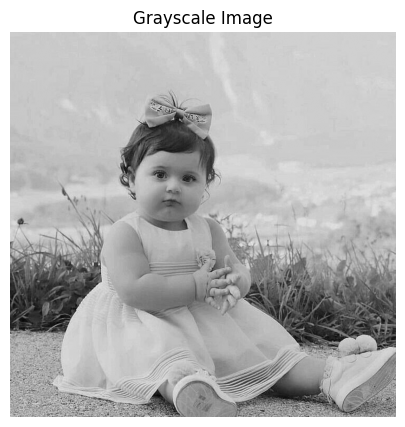

In [17]:
gray = to_grayscale(image)

print('Grayscale shape:', gray.shape)
print('Minimum intensity:', gray.min())
print('Maximum intensity:', gray.max())
show_image(gray, 'Grayscale Image')

## Binary Threshold

إذا كانت قيمة البكسل أكبر من Threshold تصبح 255، وإلا تصبح 0.

Unique values: [  0 255]


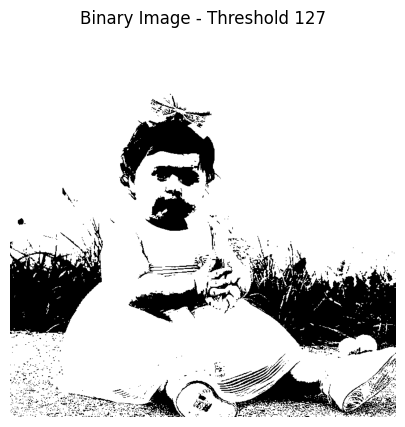

In [18]:
threshold_value = 127
binary = apply_binary_threshold(gray, threshold_value)

print('Unique values:', np.unique(binary))
show_image(binary, f'Binary Image - Threshold {threshold_value}')

## مقارنة قيم Threshold مختلفة

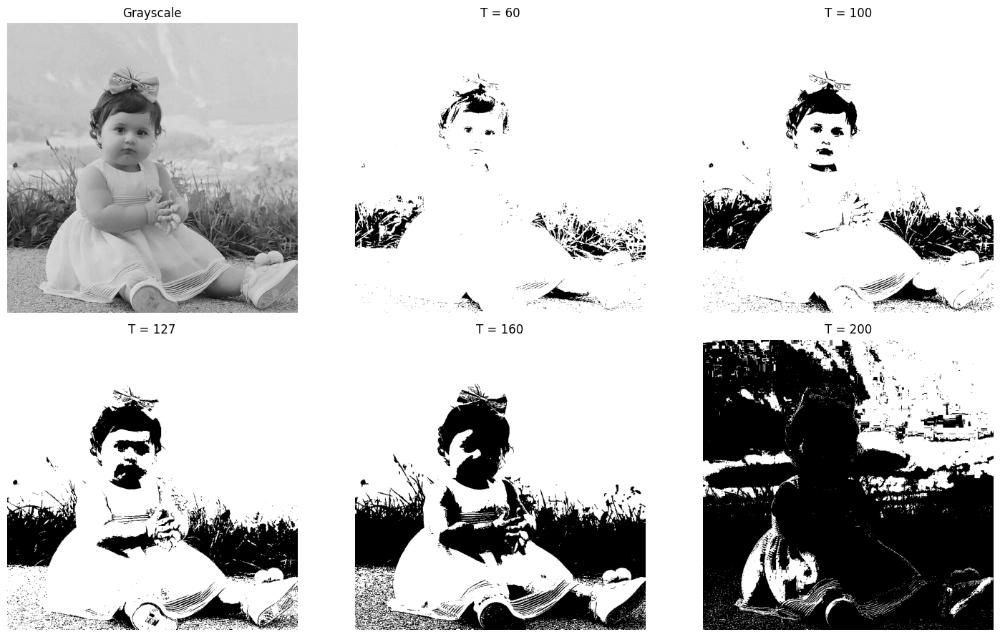

In [19]:
threshold_values = [60, 100, 127, 160, 200]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
axes[0].imshow(gray, cmap='gray')
axes[0].set_title('Grayscale')

for index, value in enumerate(threshold_values, start=1):
    result = apply_binary_threshold(gray, value)
    axes[index].imshow(result, cmap='gray')
    axes[index].set_title(f'T = {value}')

for axis in axes:
    axis.axis('off')

plt.tight_layout()
plt.show()

## Threshold يدوي باستخدام NumPy

توضح هذه الخلية منطق العملية بدل الاعتماد على دالة OpenCV فقط.

Manual result equals OpenCV result: True


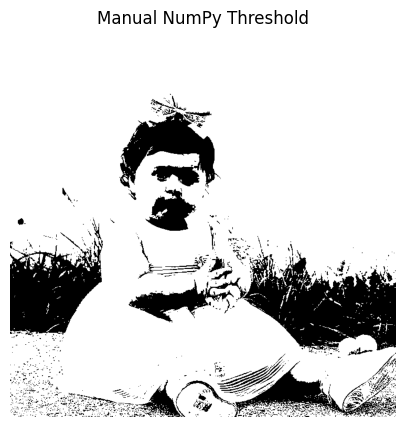

In [20]:
manual_binary = np.where(gray > threshold_value, 255, 0).astype(np.uint8)
opencv_binary = apply_binary_threshold(gray, threshold_value)

are_equal = np.array_equal(manual_binary, opencv_binary)
print('Manual result equals OpenCV result:', are_equal)
show_image(manual_binary, 'Manual NumPy Threshold')

## حفظ النتائج

In [21]:

original_path = IO_OUTPUT_DIR / '01_original.png'
gray_path = IO_OUTPUT_DIR / '01_grayscale.png'
binary_path = IO_OUTPUT_DIR / '01_binary.png'

saved_original = cv2.imwrite(str(original_path), image)
saved_gray = cv2.imwrite(str(gray_path), gray)
saved_binary = cv2.imwrite(str(binary_path), binary)

print('Original saved:', saved_original, original_path)
print('Grayscale saved:', saved_gray, gray_path)
print('Binary saved:', saved_binary, binary_path)

Original saved: True /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/01_original.png
Grayscale saved: True /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/01_grayscale.png
Binary saved: True /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/01_binary.png


## الربط بتطبيق Android

سيتم تحويل الوظائف السابقة لاحقًا إلى Kotlin باستخدام:

- `Imgproc.cvtColor()` بدل `cv2.cvtColor()`.
- `Imgproc.threshold()` بدل `cv2.threshold()`.
- `Imgcodecs.imwrite()` أو MediaStore بدل `cv2.imwrite()`.

بهذا نحتفظ بالخوارزمية نفسها، ويتغير فقط أسلوب كتابتها والتعامل مع ملفات Android.

## تمرين

1. ارفع صورة حقيقية وجرّب قيم Threshold مختلفة.
2. حدّد القيمة التي تفصل الجسم عن الخلفية بصورة أفضل.
3. قارن حجم الصورة الملونة بحجم مصفوفة Grayscale.

---

## القسم المدمج: Geometric Transformations

> المصدر الأصلي: `02_Geometric_Transformations.ipynb`. تم الحفاظ على مسارات البيانات والمخرجات الأصلية، مع إعادة تسمية بعض المتغيرات/الدوال فقط لمنع التعارض داخل الدفتر الموحّد.


## 02 - التحويلات الهندسية للصور

يغطي هذا الدفتر موضوعات LAB3: القص (ROI)، تغيير الحجم، التدوير، الإزاحة، والقلب. يطلب من المستخدم رفع صورة أو عدة صور، ويعرض النتائج للمقارنة، ثم يحفظها داخل Google Drive.

## أهداف الدفتر

- رفع صورة أو عدة صور من الجهاز.
- تنفيذ Center Crop بطريقة تناسب أي حجم للصورة.
- المقارنة بين التكبير والتصغير وطرق Interpolation.
- تدوير الصورة بزوايا موجبة وسالبة.
- إزاحة الصورة أفقيًا وعموديًا.
- قلب الصورة أفقيًا وعموديًا.
- تجربة الأدوات بصورة تفاعلية.
- حفظ النتائج تلقائيًا في Google Drive.

## 1. استيراد المكتبات وربط Google Drive

عند تشغيل الدفتر داخل Colab سيطلب السماح بالوصول إلى Drive. وعند تشغيله خارج Colab يستخدم مجلدًا محليًا للاختبار.

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

GEOMETRIC_INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
GEOMETRIC_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/02_Geometric_Transformations'
)

GEOMETRIC_INPUT_DIR.mkdir(parents=True, exist_ok=True)
GEOMETRIC_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Input directory:', GEOMETRIC_INPUT_DIR)
print('Output directory:', GEOMETRIC_OUTPUT_DIR)

Mounted at /content/drive
Running in Colab: True
Input directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/02_Geometric_Transformations


## 2. دوال العرض والمعالجة

وضع العمليات داخل دوال يجعل إعادة استخدامها في الصور والفيديو وتطبيق Android أسهل.

In [2]:
def geo_to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def geo_show_comparison(results, columns=3, figure_width=16):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, image) in zip(axes.ravel(), items):
        axis.imshow(geo_to_rgb(image), cmap='gray' if image.ndim == 2 else None)
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def center_crop(image, width_ratio=0.60, height_ratio=0.60):
    height, width = image.shape[:2]
    crop_width = max(1, int(width * width_ratio))
    crop_height = max(1, int(height * height_ratio))
    x1 = (width - crop_width) // 2
    y1 = (height - crop_height) // 2
    x2 = x1 + crop_width
    y2 = y1 + crop_height
    return image[y1:y2, x1:x2].copy()


def crop_by_percent(image, x_start, x_end, y_start, y_end):
    height, width = image.shape[:2]
    x1 = int(width * x_start / 100)
    x2 = int(width * x_end / 100)
    y1 = int(height * y_start / 100)
    y2 = int(height * y_end / 100)
    return image[y1:y2, x1:x2].copy()


def resize_by_scale(image, scale, interpolation):
    height, width = image.shape[:2]
    new_width = max(1, int(width * scale))
    new_height = max(1, int(height * scale))
    return cv2.resize(
        image, (new_width, new_height), interpolation=interpolation
    )


def rotate_image(image, angle, scale=1.0):
    height, width = image.shape[:2]
    center = (width // 2, height // 2)
    matrix = cv2.getRotationMatrix2D(center, angle, scale)
    return cv2.warpAffine(
        image, matrix, (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )


def translate_image(image, tx, ty):
    height, width = image.shape[:2]
    matrix = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(
        image, matrix, (width, height),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )


def flip_image(image, mode):
    # mode=1 أفقي، mode=0 عمودي، mode=-1 كلاهما
    return cv2.flip(image, mode)

## 3. رفع صورة أو عدة صور

يمكن تحديد عدة صور من نافذة الرفع. تُحفظ كل صورة أصلية داخل مجلد `02_Data/Images/Input`.

In [3]:
# ============================================================
# قراءة الصور من Google Drive
# والرفع الاختياري عند إضافة صور جديدة
# ============================================================

# اجعلها True فقط عند إضافة صور جديدة
UPLOAD_NEW_FILES = False

SUPPORTED_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

uploaded_images = {}


# ============================================================
# 1. قراءة الصور الموجودة في مجلد Input
# ============================================================

existing_image_paths = sorted([
    path
    for path in GEOMETRIC_INPUT_DIR.iterdir()
    if (
        path.is_file()
        and path.suffix.lower()
        in SUPPORTED_EXTENSIONS
    )
])

for image_path in existing_image_paths:

    loaded_image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    if loaded_image is None:
        print(
            f"تعذر قراءة الصورة: "
            f"{image_path.name}"
        )
        continue

    uploaded_images[
        image_path.name
    ] = loaded_image


print(
    "عدد الصور الموجودة في Drive:",
    len(uploaded_images)
)


# ============================================================
# 2. رفع صور جديدة عند الحاجة فقط
# ============================================================

if IN_COLAB and UPLOAD_NEW_FILES:

    from google.colab import files

    print("اختر صورة أو عدة صور:")

    uploaded_files = files.upload()

    for file_name, file_data in uploaded_files.items():

        image_array = np.frombuffer(
            file_data,
            dtype=np.uint8
        )

        loaded_image = cv2.imdecode(
            image_array,
            cv2.IMREAD_COLOR
        )

        if loaded_image is None:
            print(
                f"تعذر قراءة الملف: "
                f"{file_name}"
            )
            continue

        safe_file_name = Path(
            file_name
        ).name

        input_path = (
            GEOMETRIC_INPUT_DIR / safe_file_name
        )

        save_success = cv2.imwrite(
            str(input_path),
            loaded_image
        )

        if not save_success:
            print(
                f"فشل حفظ الصورة: "
                f"{safe_file_name}"
            )
            continue

        uploaded_images[
            safe_file_name
        ] = loaded_image

        print(
            f"تمت إضافة الصورة: "
            f"{safe_file_name}"
        )


# ============================================================
# 3. التحقق من وجود صور
# ============================================================

if not uploaded_images:

    raise ValueError(
        "لا توجد صور داخل مجلد Input.\n"
        "ضع صورة في المجلد أو اجعل:\n"
        "UPLOAD_NEW_FILES = True"
    )


# ============================================================
# 4. عرض الصور المتاحة
# ============================================================

print(
    f"\nعدد الصور الجاهزة للمعالجة: "
    f"{len(uploaded_images)}"
)

for index, (
    file_name,
    loaded_image
) in enumerate(
    uploaded_images.items(),
    start=1
):

    print(
        f"{index}. {file_name} "
        f"- الأبعاد: {loaded_image.shape}"
    )

عدد الصور الموجودة في Drive: 4

عدد الصور الجاهزة للمعالجة: 4
1. R.jpeg - الأبعاد: (736, 736, 3)
2. balloons.jpg - الأبعاد: (547, 602, 3)
3. children.jpeg - الأبعاد: (774, 1376, 3)
4. coins.jpg - الأبعاد: (390, 400, 3)


## 4. اختيار الصورة المستخدمة في العرض التفاعلي

تُعالج جميع الصور لاحقًا، لكن أول صورة تُستخدم في المقارنات والأدوات التفاعلية.

Selected image: R.jpeg
Width: 736
Height: 736


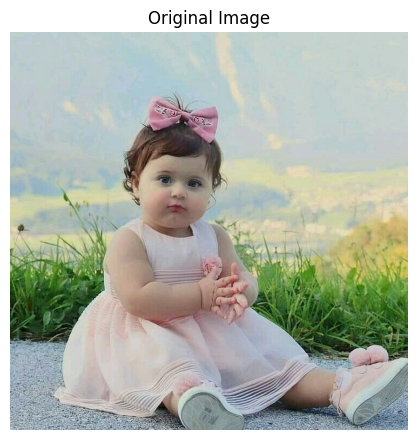

In [4]:
selected_name = next(iter(uploaded_images))
image = uploaded_images[selected_name]
height, width = image.shape[:2]

print('Selected image:', selected_name)
print('Width:', width)
print('Height:', height)

geo_show_comparison({'Original Image': image}, columns=1, figure_width=8)

## 5. القص - Region of Interest (ROI)

يتم تخزين الصورة على شكل `image[y1:y2, x1:x2]`. هنا نقص 60% من منتصف الصورة حتى يعمل المثال مع أي أبعاد.

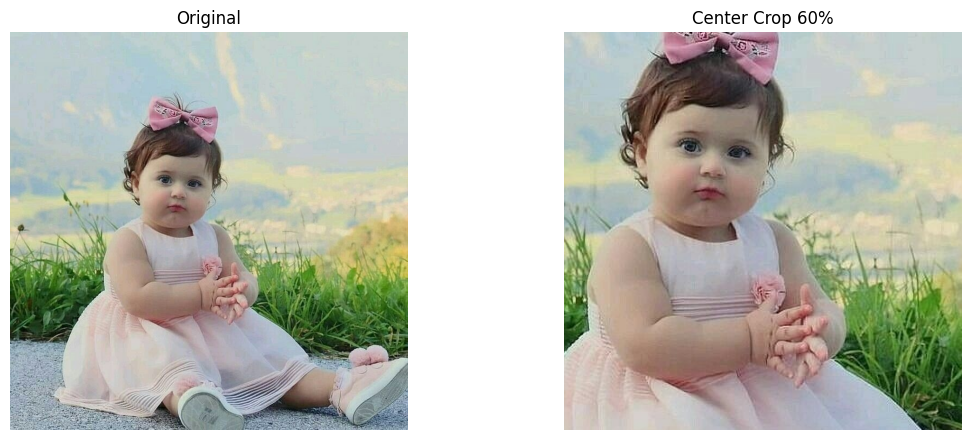

Original shape: (736, 736, 3)
Cropped shape: (441, 441, 3)


In [5]:
cropped = center_crop(image, width_ratio=0.60, height_ratio=0.60)

geo_show_comparison(
    {
        'Original': image,
        'Center Crop 60%': cropped
    },
    columns=2,
    figure_width=12
)

print('Original shape:', image.shape)
print('Cropped shape:', cropped.shape)

## 6. تغيير الحجم - Resize

نستخدم `INTER_CUBIC` عند التكبير للحصول على نتيجة أنعم، و`INTER_AREA` عند التصغير لتقليل فقد التفاصيل.

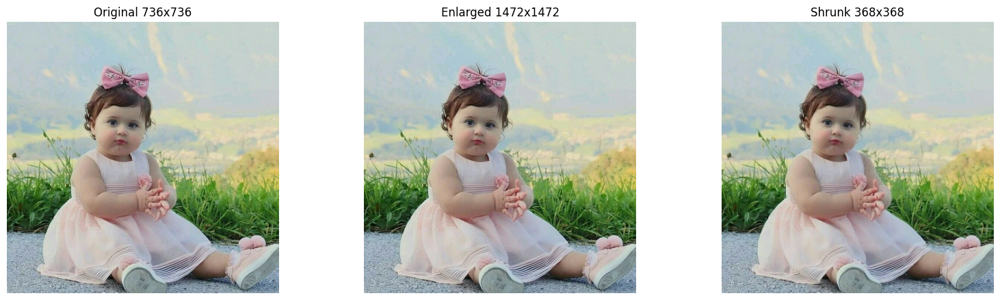

In [6]:
enlarged = resize_by_scale(image, 2.0, cv2.INTER_CUBIC)
shrunk = resize_by_scale(image, 0.5, cv2.INTER_AREA)

geo_show_comparison(
    {
        f'Original {width}x{height}': image,
        f'Enlarged {enlarged.shape[1]}x{enlarged.shape[0]}': enlarged,
        f'Shrunk {shrunk.shape[1]}x{shrunk.shape[0]}': shrunk
    },
    columns=3
)

## 7. التدوير والإزاحة والقلب

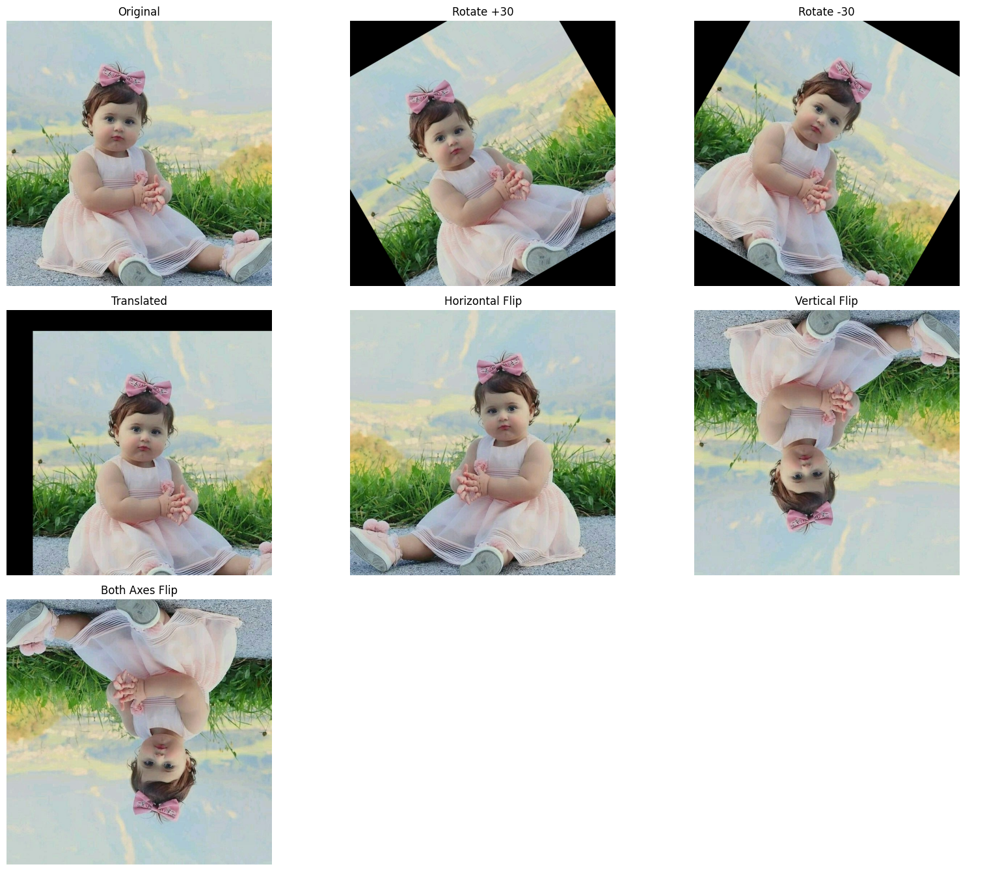

In [7]:
rotated_positive = rotate_image(image, 30)
rotated_negative = rotate_image(image, -30)
translated = translate_image(
    image, tx=int(width * 0.10), ty=int(height * 0.08)
)
flipped_horizontal = flip_image(image, 1)
flipped_vertical = flip_image(image, 0)
flipped_both = flip_image(image, -1)

geo_show_comparison(
    {
        'Original': image,
        'Rotate +30': rotated_positive,
        'Rotate -30': rotated_negative,
        'Translated': translated,
        'Horizontal Flip': flipped_horizontal,
        'Vertical Flip': flipped_vertical,
        'Both Axes Flip': flipped_both
    },
    columns=3
)

## 8. أداة تفاعلية للتدوير والتكبير والإزاحة

حرّك القيم لمشاهدة التأثير مباشرة على الصورة.

In [8]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')

def interactive_transform(angle=0, scale=1.0, tx=0, ty=0):
    result = rotate_image(image, angle, scale)
    result = translate_image(result, tx, ty)

    geo_show_comparison(
        {
            'Original': image,
            f'Angle={angle}, Scale={scale:.2f}, Move=({tx}, {ty})': result
        },
        columns=2,
        figure_width=12
    )

if WIDGETS_AVAILABLE:
    transform_controls = widgets.interactive(
        interactive_transform,
        angle=widgets.IntSlider(
            value=0, min=-180, max=180, step=5, description='Angle'
        ),
        scale=widgets.FloatSlider(
            value=1.0, min=0.25, max=2.0, step=0.05, description='Scale'
        ),
        tx=widgets.IntSlider(
            value=0, min=-width // 2, max=width // 2,
            step=5, description='Move X'
        ),
        ty=widgets.IntSlider(
            value=0, min=-height // 2, max=height // 2,
            step=5, description='Move Y'
        )
    )
    display(transform_controls)

interactive(children=(IntSlider(value=0, description='Angle', max=180, min=-180, step=5), FloatSlider(value=1.…

## 9. أداة تفاعلية لاختيار منطقة القص

القيم تمثل النسبة المئوية من عرض الصورة وارتفاعها. يجب أن تكون بداية النطاق أصغر من نهايته.

In [9]:
def interactive_crop(x_range=(20, 80), y_range=(20, 80)):
    x_start, x_end = x_range
    y_start, y_end = y_range
    result = crop_by_percent(
        image, x_start, x_end, y_start, y_end
    )

    geo_show_comparison(
        {
            'Original': image,
            f'Crop X={x_range}%, Y={y_range}%': result
        },
        columns=2,
        figure_width=12
    )

if WIDGETS_AVAILABLE:
    crop_controls = widgets.interactive(
        interactive_crop,
        x_range=widgets.IntRangeSlider(
            value=[20, 80], min=0, max=100, step=1,
            description='X Range'
        ),
        y_range=widgets.IntRangeSlider(
            value=[20, 80], min=0, max=100, step=1,
            description='Y Range'
        )
    )
    display(crop_controls)
else:
    print('شغّل هذه الخلية داخل Colab لعرض أداة القص التفاعلية.')

interactive(children=(IntRangeSlider(value=(20, 80), description='X Range'), IntRangeSlider(value=(20, 80), de…

## 10. معالجة جميع الصور وحفظ النتائج

تُنشأ لكل صورة مجلد مستقل حتى لا تختلط النتائج عند رفع عدة صور.

In [10]:
saved_files = []

for file_name, source_image in uploaded_images.items():
    stem = Path(file_name).stem
    image_output_dir = GEOMETRIC_OUTPUT_DIR / stem
    image_output_dir.mkdir(parents=True, exist_ok=True)

    source_height, source_width = source_image.shape[:2]
    results = {
        '00_original.png': source_image,
        '01_center_crop.png': center_crop(source_image),
        '02_enlarged_cubic.png': resize_by_scale(
            source_image, 2.0, cv2.INTER_CUBIC
        ),
        '03_shrunk_area.png': resize_by_scale(
            source_image, 0.5, cv2.INTER_AREA
        ),
        '04_rotated_positive_30.png': rotate_image(source_image, 30),
        '05_rotated_negative_30.png': rotate_image(source_image, -30),
        '06_translated.png': translate_image(
            source_image,
            int(source_width * 0.10),
            int(source_height * 0.08)
        ),
        '07_flip_horizontal.png': flip_image(source_image, 1),
        '08_flip_vertical.png': flip_image(source_image, 0),
        '09_flip_both.png': flip_image(source_image, -1)
    }

    for output_name, result_image in results.items():
        output_path = image_output_dir / output_name
        if not cv2.imwrite(str(output_path), result_image):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_files.append(output_path)

print(f'تم حفظ {len(saved_files)} ملفًا بنجاح.')
print('مجلد النتائج:', GEOMETRIC_OUTPUT_DIR)
for path in saved_files:
    print('-', path.name)

تم حفظ 40 ملفًا بنجاح.
مجلد النتائج: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/02_Geometric_Transformations
- 00_original.png
- 01_center_crop.png
- 02_enlarged_cubic.png
- 03_shrunk_area.png
- 04_rotated_positive_30.png
- 05_rotated_negative_30.png
- 06_translated.png
- 07_flip_horizontal.png
- 08_flip_vertical.png
- 09_flip_both.png
- 00_original.png
- 01_center_crop.png
- 02_enlarged_cubic.png
- 03_shrunk_area.png
- 04_rotated_positive_30.png
- 05_rotated_negative_30.png
- 06_translated.png
- 07_flip_horizontal.png
- 08_flip_vertical.png
- 09_flip_both.png
- 00_original.png
- 01_center_crop.png
- 02_enlarged_cubic.png
- 03_shrunk_area.png
- 04_rotated_positive_30.png
- 05_rotated_negative_30.png
- 06_translated.png
- 07_flip_horizontal.png
- 08_flip_vertical.png
- 09_flip_both.png
- 00_original.png
- 01_center_crop.png
- 02_enlarged_cubic.png
- 03_shrunk_area.png
- 04_rotated_positive_30.png
- 05_rotated_negative_30.png
- 06_translated.png
- 07_fl

## 11. الربط بتطبيق Android

ستُنقل الخوارزميات لاحقًا إلى Kotlin باستخدام:

- `Imgproc.resize()` لتغيير الحجم.
- `Imgproc.getRotationMatrix2D()` و`Imgproc.warpAffine()` للتدوير.
- `Imgproc.warpAffine()` للإزاحة.
- `Core.flip()` للقلب.
- اختيار ROI من `Mat` لتنفيذ القص.

وسيستخدم تطبيق Android القيم نفسها التي تم اختبارها في هذا الدفتر.

## 12. تمارين مقترحة

1. ارفع صورتين بأبعاد مختلفة وتأكد أن Center Crop يعمل معهما.
2. قارن `INTER_CUBIC` و`INTER_LINEAR` عند تكبير الصورة.
3. جرّب تدوير الصورة بزاوية 45 و90 و180 درجة.
4. لاحظ المناطق السوداء التي تظهر بعد التدوير والإزاحة، وفكّر في طرق معالجتها.

---

## القسم المدمج: Filters & Enhancement

> المصدر الأصلي: `03_Image_Filters_Enhancement.ipynb`. تم الحفاظ على مسارات البيانات والمخرجات الأصلية، مع إعادة تسمية بعض المتغيرات/الدوال فقط لمنع التعارض داخل الدفتر الموحّد.


## 03 - فلاتر وتحسين الصور

يجمع هذا الدفتر تقنيات تحسين الإضاءة والتباين والتحويلات النقطية من LAB5، وتقنيات Histogram وSmoothing Filters من LAB6. يتيح رفع صورة أو عدة صور، والمقارنة التفاعلية، والحفظ في Google Drive.

## أهداف الدفتر

- رفع صورة أو عدة صور من الجهاز.
- تحسين السطوع والتباين.
- تطبيق Log وGamma Transformation.
- عرض Histogram قبل التحسين وبعده.
- تطبيق Histogram Equalization على الصورة الرمادية.
- مقارنة Average وGaussian وMedian وBilateral.
- استخدام filter2D وSharpening Kernel.
- تغيير القيم تفاعليًا ثم حفظ النتائج.

## 1. استيراد المكتبات وربط Google Drive

In [32]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

FILTERS_INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
FILTERS_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/03_Filters_Enhancement'
)

FILTERS_INPUT_DIR.mkdir(parents=True, exist_ok=True)
FILTERS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Input directory:', FILTERS_INPUT_DIR)
print('Output directory:', FILTERS_OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
Input directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/03_Filters_Enhancement


## 2. دوال العرض والتحقق

يجب أن يكون حجم Kernel عددًا فرديًا مثل 3 أو 5 أو 7، لأن الفلتر يحتاج بكسلًا مركزيًا.

In [33]:
def filters_to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def filters_show_comparison(results, columns=3, figure_width=16):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, result) in zip(axes.ravel(), items):
        axis.imshow(
            filters_to_rgb(result),
            cmap='gray' if result.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def valid_kernel_size(kernel_size):
    kernel_size = int(kernel_size)
    if kernel_size < 1:
        kernel_size = 1
    if kernel_size % 2 == 0:
        kernel_size += 1
    return kernel_size

## 3. دوال تحسين الصورة والفلاتر

In [34]:
def adjust_brightness_contrast(image, brightness=0, contrast=1.0):
    result = image.astype(np.float32) * float(contrast) + float(brightness)
    return np.clip(result, 0, 255).astype(np.uint8)


def gamma_correction(image, gamma=1.0):
    if gamma <= 0:
        raise ValueError('Gamma must be greater than zero.')
    normalized = image.astype(np.float32) / 255.0
    corrected = np.power(normalized, gamma)
    return np.clip(corrected * 255, 0, 255).astype(np.uint8)


def log_transform(image):
    float_image = image.astype(np.float32)
    maximum = float(np.max(float_image))
    if maximum == 0:
        return image.copy()
    constant = 255.0 / np.log1p(maximum)
    result = constant * np.log1p(float_image)
    return np.clip(result, 0, 255).astype(np.uint8)


def equalize_grayscale(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return gray, cv2.equalizeHist(gray)


def equalize_color_luminance(image):
    ycrcb = cv2.cvtColor(image, cv2.COLOR_BGR2YCrCb)
    ycrcb[:, :, 0] = cv2.equalizeHist(ycrcb[:, :, 0])
    return cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)


def average_filter(image, kernel_size=5):
    k = valid_kernel_size(kernel_size)
    return cv2.blur(image, (k, k))


def gaussian_filter(image, kernel_size=5, sigma=0):
    k = valid_kernel_size(kernel_size)
    return cv2.GaussianBlur(image, (k, k), sigma)


def median_filter(image, kernel_size=5):
    k = max(3, valid_kernel_size(kernel_size))
    return cv2.medianBlur(image, k)


def bilateral_filter(image, diameter=9, sigma_color=75, sigma_space=75):
    return cv2.bilateralFilter(
        image, int(diameter), float(sigma_color), float(sigma_space)
    )


def custom_filter2d(image, kernel_size=5):
    k = valid_kernel_size(kernel_size)
    kernel = np.ones((k, k), dtype=np.float32) / (k * k)
    return cv2.filter2D(image, ddepth=-1, kernel=kernel)


def sharpen_image(image):
    kernel = np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ], dtype=np.float32)
    return cv2.filter2D(image, ddepth=-1, kernel=kernel)

## 4. رفع صورة أو عدة صور

يمكن اختيار أكثر من صورة. تُحفظ الصور الأصلية داخل مجلد الإدخال قبل المعالجة.

In [35]:
# ============================================================
# قراءة الصور من Google Drive
# مع إمكانية رفع صور جديدة عند الحاجة فقط
# ============================================================

# اجعلها True فقط عندما تريد إضافة صور جديدة
UPLOAD_NEW_FILES = False

# صيغ الصور المدعومة
SUPPORTED_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

# سيحتوي هذا القاموس على جميع الصور
uploaded_images = {}


# ============================================================
# 1. قراءة الصور الموجودة مسبقًا داخل مجلد Input
# ============================================================

existing_image_paths = sorted([
    path
    for path in FILTERS_INPUT_DIR.iterdir()
    if (
        path.is_file()
        and path.suffix.lower()
        in SUPPORTED_EXTENSIONS
    )
])

for image_path in existing_image_paths:

    loaded_image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    if loaded_image is None:
        print(
            f"تعذر قراءة الصورة: "
            f"{image_path.name}"
        )
        continue

    uploaded_images[
        image_path.name
    ] = loaded_image


print(
    "عدد الصور الموجودة مسبقًا في Drive:",
    len(uploaded_images)
)


# ============================================================
# 2. رفع صور جديدة عند الحاجة
# ============================================================

if IN_COLAB and UPLOAD_NEW_FILES:

    from google.colab import files

    print(
        "اختر صورة أو عدة صور من جهازك:"
    )

    uploaded_files = files.upload()

    for file_name, file_data in uploaded_files.items():

        # تحويل بيانات الصورة إلى مصفوفة NumPy
        image_array = np.frombuffer(
            file_data,
            dtype=np.uint8
        )

        # فك ترميز الصورة باستخدام OpenCV
        loaded_image = cv2.imdecode(
            image_array,
            cv2.IMREAD_COLOR
        )

        if loaded_image is None:
            print(
                f"تعذر قراءة الملف: "
                f"{file_name}"
            )
            continue

        # الحصول على اسم الملف فقط
        safe_file_name = Path(
            file_name
        ).name

        # مكان حفظ الصورة داخل Google Drive
        input_path = (
            FILTERS_INPUT_DIR / safe_file_name
        )

        # حفظ الصورة حتى لا تحتاج إلى رفعها مرة أخرى
        save_success = cv2.imwrite(
            str(input_path),
            loaded_image
        )

        if not save_success:
            print(
                f"فشل حفظ الصورة: "
                f"{safe_file_name}"
            )
            continue

        # إضافة الصورة إلى قاموس الصور
        uploaded_images[
            safe_file_name
        ] = loaded_image

        print(
            f"تمت إضافة وحفظ الصورة: "
            f"{safe_file_name}"
        )


# ============================================================
# 3. التأكد من وجود صورة واحدة على الأقل
# ============================================================

if not uploaded_images:

    raise ValueError(
        "لا توجد صور داخل مجلد Input.\n"
        "ضع صورة داخل المجلد:\n"
        f"{FILTERS_INPUT_DIR}\n"
        "أو اجعل:\n"
        "UPLOAD_NEW_FILES = True"
    )


# ============================================================
# 4. عرض الصور الجاهزة للمعالجة
# ============================================================

print(
    f"\nعدد الصور الجاهزة للمعالجة: "
    f"{len(uploaded_images)}"
)

for index, (
    file_name,
    loaded_image
) in enumerate(
    uploaded_images.items(),
    start=1
):

    print(
        f"{index}. {file_name} "
        f"- الأبعاد: {loaded_image.shape}"
    )

عدد الصور الموجودة مسبقًا في Drive: 4

عدد الصور الجاهزة للمعالجة: 4
1. R.jpeg - الأبعاد: (736, 736, 3)
2. balloons.jpg - الأبعاد: (547, 602, 3)
3. children.jpeg - الأبعاد: (774, 1376, 3)
4. coins.jpg - الأبعاد: (390, 400, 3)


## 5. اختيار صورة المقارنة

تُستخدم أول صورة في العروض التفاعلية، ثم تُعالج جميع الصور في قسم الحفظ النهائي.

Selected image: R.jpeg
Shape: (736, 736, 3)
Data type: uint8


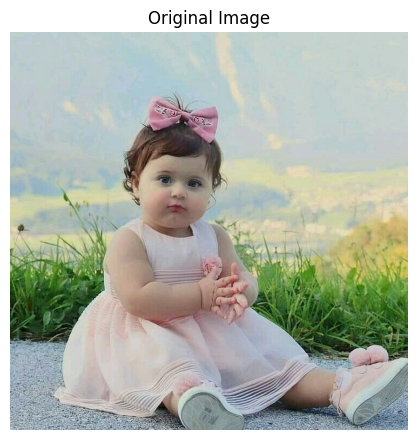

In [25]:
selected_name = next(iter(uploaded_images))
image = uploaded_images[selected_name]

print('Selected image:', selected_name)
print('Shape:', image.shape)
print('Data type:', image.dtype)
filters_show_comparison({'Original Image': image}, columns=1, figure_width=8)

## 6. السطوع والتباين وLog وGamma Transformation

- السطوع يضيف قيمة إلى البكسلات.
- التباين يوسّع أو يضيّق الفرق بين القيم.
- Log Transformation يبرز التفاصيل الداكنة.
- Gamma أقل من 1 يفتح الصورة، وأكبر من 1 يجعلها أغمق وفق الصيغة المستخدمة هنا.

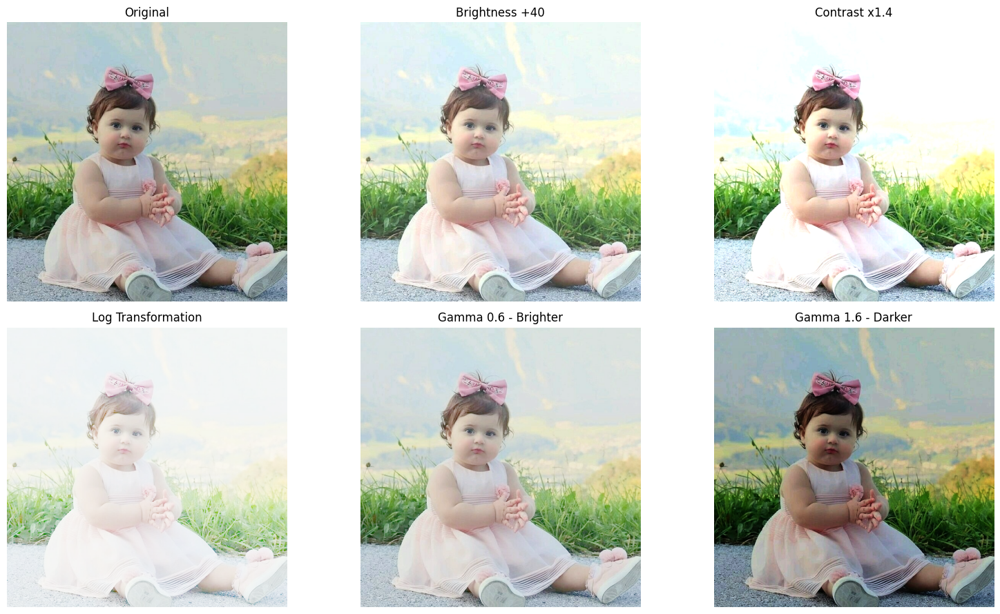

In [26]:
brighter = adjust_brightness_contrast(image, brightness=40, contrast=1.0)
higher_contrast = adjust_brightness_contrast(
    image, brightness=0, contrast=1.4
)
log_result = log_transform(image)
gamma_bright = gamma_correction(image, gamma=0.6)
gamma_dark = gamma_correction(image, gamma=1.6)

filters_show_comparison(
    {
        'Original': image,
        'Brightness +40': brighter,
        'Contrast x1.4': higher_contrast,
        'Log Transformation': log_result,
        'Gamma 0.6 - Brighter': gamma_bright,
        'Gamma 1.6 - Darker': gamma_dark
    },
    columns=3
)

## 7. Histogram Equalization

نقارن توزيع شدة الإضاءة قبل Equalization وبعده. كما نطبّق التحسين على قناة الإضاءة في الصورة الملونة حتى لا تتشوّه الألوان.

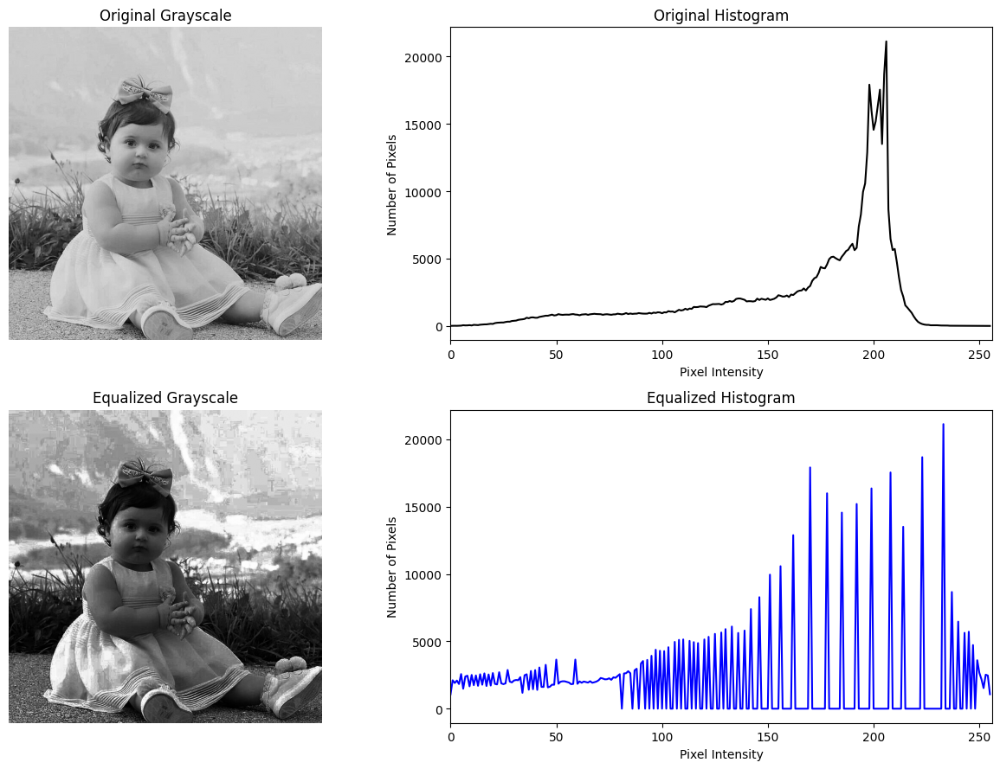

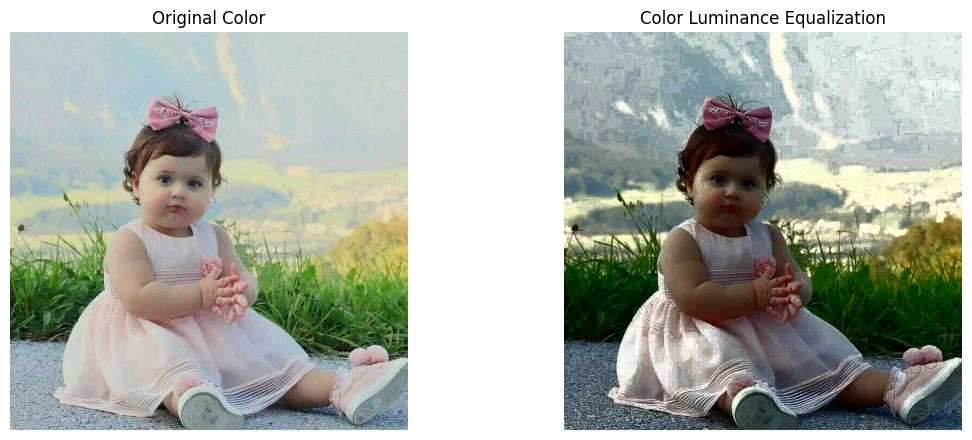

In [27]:
gray, equalized_gray = equalize_grayscale(image)
equalized_color = equalize_color_luminance(image)

hist_original = cv2.calcHist([gray], [0], None, [256], [0, 256])
hist_equalized = cv2.calcHist(
    [equalized_gray], [0], None, [256], [0, 256]
)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].imshow(gray, cmap='gray')
axes[0, 0].set_title('Original Grayscale')
axes[0, 0].axis('off')
axes[0, 1].plot(hist_original, color='black')
axes[0, 1].set_title('Original Histogram')
axes[0, 1].set_xlim([0, 256])
axes[0, 1].set_xlabel('Pixel Intensity')
axes[0, 1].set_ylabel('Number of Pixels')
axes[1, 0].imshow(equalized_gray, cmap='gray')
axes[1, 0].set_title('Equalized Grayscale')
axes[1, 0].axis('off')
axes[1, 1].plot(hist_equalized, color='blue')
axes[1, 1].set_title('Equalized Histogram')
axes[1, 1].set_xlim([0, 256])
axes[1, 1].set_xlabel('Pixel Intensity')
axes[1, 1].set_ylabel('Number of Pixels')
plt.tight_layout()
plt.show()

filters_show_comparison(
    {
        'Original Color': image,
        'Color Luminance Equalization': equalized_color
    },
    columns=2,
    figure_width=12
)

## 8. مقارنة فلاتر التنعيم والحدة

- Average سريع لكنه يطمس الحواف.
- Gaussian يعطي تنعيمًا طبيعيًا.
- Median مناسب لضوضاء Salt-and-Pepper.
- Bilateral يقلل الضوضاء مع المحافظة على الحواف بصورة أفضل.

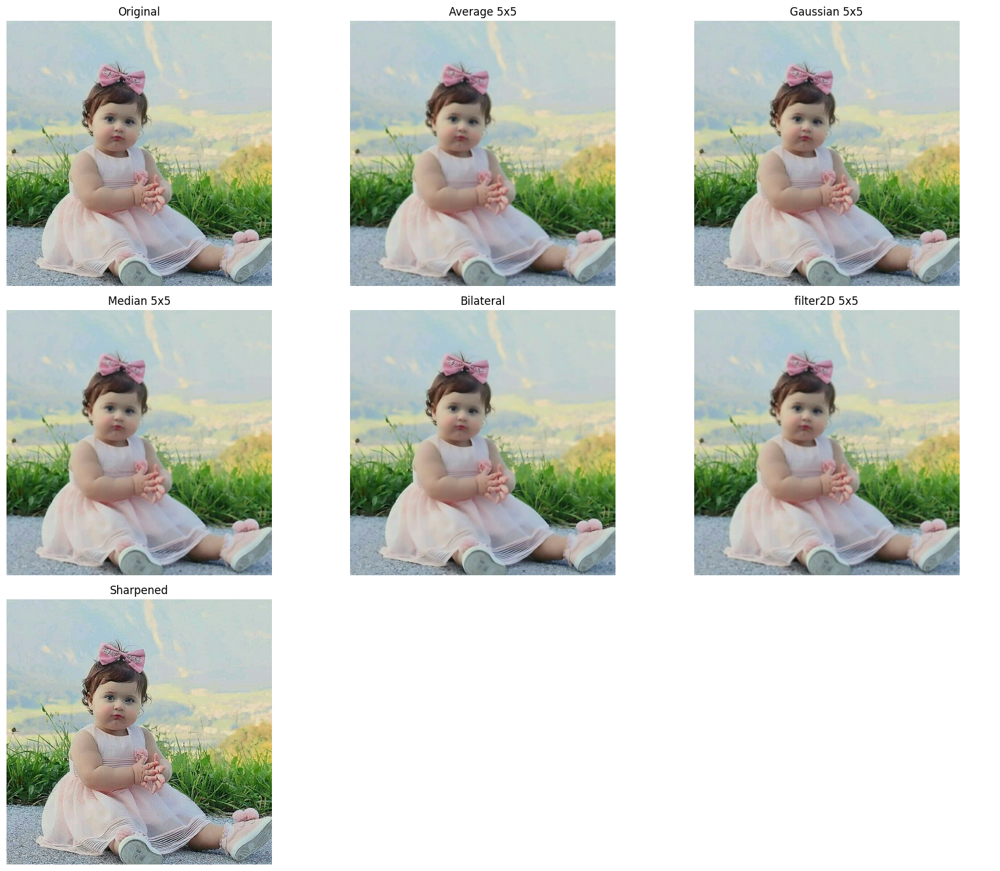

In [28]:
average_result = average_filter(image, 5)
gaussian_result = gaussian_filter(image, 5)
median_result = median_filter(image, 5)
bilateral_result = bilateral_filter(image, 9, 75, 75)
filter2d_result = custom_filter2d(image, 5)
sharpened_result = sharpen_image(image)

filters_show_comparison(
    {
        'Original': image,
        'Average 5x5': average_result,
        'Gaussian 5x5': gaussian_result,
        'Median 5x5': median_result,
        'Bilateral': bilateral_result,
        'filter2D 5x5': filter2d_result,
        'Sharpened': sharpened_result
    },
    columns=3
)

## 9. أداة تفاعلية لمقارنة الفلاتر

اختر الفلتر وغيّر Kernel Size. عند اختيار Bilateral تُستخدم قيم Sigma أيضًا.

In [29]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')


def interactive_filter(
    filter_name='Gaussian', kernel_size=5, sigma=0.0,
    sigma_color=75, sigma_space=75
):
    k = valid_kernel_size(kernel_size)

    if filter_name == 'Average':
        result = average_filter(image, k)
    elif filter_name == 'Gaussian':
        result = gaussian_filter(image, k, sigma)
    elif filter_name == 'Median':
        result = median_filter(image, k)
    elif filter_name == 'Bilateral':
        result = bilateral_filter(
            image, k, sigma_color, sigma_space
        )
    elif filter_name == 'filter2D':
        result = custom_filter2d(image, k)
    else:
        result = sharpen_image(image)

    filters_show_comparison(
        {
            'Original': image,
            f'{filter_name} - Kernel {k}': result
        },
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    filter_controls = widgets.interactive(
        interactive_filter,
        filter_name=widgets.Dropdown(
            options=[
                'Average', 'Gaussian', 'Median',
                'Bilateral', 'filter2D', 'Sharpen'
            ],
            value='Gaussian',
            description='Filter'
        ),
        kernel_size=widgets.IntSlider(
            value=5, min=1, max=15, step=2, description='Kernel'
        ),
        sigma=widgets.FloatSlider(
            value=0.0, min=0.0, max=10.0, step=0.5, description='Sigma'
        ),
        sigma_color=widgets.IntSlider(
            value=75, min=10, max=200, step=5, description='Color'
        ),
        sigma_space=widgets.IntSlider(
            value=75, min=10, max=200, step=5, description='Space'
        )
    )
    display(filter_controls)

interactive(children=(Dropdown(description='Filter', index=1, options=('Average', 'Gaussian', 'Median', 'Bilat…

## 10. أداة تفاعلية للسطوع والتباين وGamma

In [30]:
def interactive_enhancement(brightness=0, contrast=1.0, gamma=1.0):
    adjusted = adjust_brightness_contrast(
        image, brightness=brightness, contrast=contrast
    )
    result = gamma_correction(adjusted, gamma=gamma)

    filters_show_comparison(
        {
            'Original': image,
            (
                f'Brightness={brightness}, Contrast={contrast:.2f}, '
                f'Gamma={gamma:.2f}'
            ): result
        },
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    enhancement_controls = widgets.interactive(
        interactive_enhancement,
        brightness=widgets.IntSlider(
            value=0, min=-100, max=100, step=5,
            description='Brightness'
        ),
        contrast=widgets.FloatSlider(
            value=1.0, min=0.2, max=3.0, step=0.1,
            description='Contrast'
        ),
        gamma=widgets.FloatSlider(
            value=1.0, min=0.2, max=3.0, step=0.1,
            description='Gamma'
        )
    )
    display(enhancement_controls)
else:
    print('شغّل الخلية داخل Colab لعرض أدوات التحسين التفاعلية.')

interactive(children=(IntSlider(value=0, description='Brightness', min=-100, step=5), FloatSlider(value=1.0, d…

## 11. معالجة جميع الصور وحفظ النتائج

ينشئ الدفتر مجلدًا مستقلًا لكل صورة، ويحفظ الصور المعالجة ورسم Histogram.

In [31]:
saved_files = []

for file_name, source_image in uploaded_images.items():
    stem = Path(file_name).stem
    image_output_dir = FILTERS_OUTPUT_DIR / stem
    image_output_dir.mkdir(parents=True, exist_ok=True)

    source_gray, source_equalized = equalize_grayscale(source_image)
    results = {
        '00_original.png': source_image,
        '01_grayscale.png': source_gray,
        '02_histogram_equalized_gray.png': source_equalized,
        '03_histogram_equalized_color.png': (
            equalize_color_luminance(source_image)
        ),
        '04_brightness_plus_40.png': adjust_brightness_contrast(
            source_image, brightness=40
        ),
        '05_contrast_1_4.png': adjust_brightness_contrast(
            source_image, contrast=1.4
        ),
        '06_log_transformation.png': log_transform(source_image),
        '07_gamma_0_6.png': gamma_correction(source_image, 0.6),
        '08_average_5x5.png': average_filter(source_image, 5),
        '09_gaussian_5x5.png': gaussian_filter(source_image, 5),
        '10_median_5x5.png': median_filter(source_image, 5),
        '11_bilateral.png': bilateral_filter(source_image, 9, 75, 75),
        '12_filter2d_5x5.png': custom_filter2d(source_image, 5),
        '13_sharpened.png': sharpen_image(source_image)
    }

    for output_name, result_image in results.items():
        output_path = image_output_dir / output_name
        if not cv2.imwrite(str(output_path), result_image):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_files.append(output_path)

    original_hist = cv2.calcHist(
        [source_gray], [0], None, [256], [0, 256]
    )
    equalized_hist = cv2.calcHist(
        [source_equalized], [0], None, [256], [0, 256]
    )
    histogram_figure, histogram_axis = plt.subplots(figsize=(9, 5))
    histogram_axis.plot(original_hist, label='Original', color='black')
    histogram_axis.plot(equalized_hist, label='Equalized', color='blue')
    histogram_axis.set_title(f'Histogram Comparison - {file_name}')
    histogram_axis.set_xlabel('Pixel Intensity')
    histogram_axis.set_ylabel('Number of Pixels')
    histogram_axis.set_xlim([0, 256])
    histogram_axis.legend()
    histogram_axis.grid(alpha=0.2)
    histogram_figure.tight_layout()
    histogram_path = image_output_dir / '14_histogram_comparison.png'
    histogram_figure.savefig(histogram_path, dpi=150)
    plt.close(histogram_figure)
    saved_files.append(histogram_path)

print(f'تم حفظ {len(saved_files)} ملفًا بنجاح.')
print('مجلد النتائج:', FILTERS_OUTPUT_DIR)
for path in saved_files:
    print('-', path.name)

تم حفظ 60 ملفًا بنجاح.
مجلد النتائج: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/03_Filters_Enhancement
- 00_original.png
- 01_grayscale.png
- 02_histogram_equalized_gray.png
- 03_histogram_equalized_color.png
- 04_brightness_plus_40.png
- 05_contrast_1_4.png
- 06_log_transformation.png
- 07_gamma_0_6.png
- 08_average_5x5.png
- 09_gaussian_5x5.png
- 10_median_5x5.png
- 11_bilateral.png
- 12_filter2d_5x5.png
- 13_sharpened.png
- 14_histogram_comparison.png
- 00_original.png
- 01_grayscale.png
- 02_histogram_equalized_gray.png
- 03_histogram_equalized_color.png
- 04_brightness_plus_40.png
- 05_contrast_1_4.png
- 06_log_transformation.png
- 07_gamma_0_6.png
- 08_average_5x5.png
- 09_gaussian_5x5.png
- 10_median_5x5.png
- 11_bilateral.png
- 12_filter2d_5x5.png
- 13_sharpened.png
- 14_histogram_comparison.png
- 00_original.png
- 01_grayscale.png
- 02_histogram_equalized_gray.png
- 03_histogram_equalized_color.png
- 04_brightness_plus_40.png
- 05_contrast_1_

## 12. الربط بتطبيق Android

ستُنقل العمليات إلى Kotlin باستخدام دوال OpenCV التالية:

- `Imgproc.blur()` للـAverage Filter.
- `Imgproc.GaussianBlur()` للـGaussian.
- `Imgproc.medianBlur()` للـMedian.
- `Imgproc.bilateralFilter()` للـBilateral.
- `Imgproc.filter2D()` للمرشحات المخصصة والحدة.
- `Imgproc.equalizeHist()` لتحسين Histogram.
- `Core.LUT()` لتنفيذ Gamma بسرعة داخل الهاتف.

## 13. أسئلة للمناقشة

1. لماذا يجب أن يكون Kernel Size عددًا فرديًا؟
2. أي فلتر يحافظ على الحواف بصورة أفضل؟
3. لماذا يكون Median فعالًا مع Salt-and-Pepper Noise؟
4. ما الفرق بين زيادة السطوع وزيادة التباين؟
5. متى نستخدم Gamma أقل من 1 ومتى نستخدم Gamma أكبر من 1؟